<a href="https://colab.research.google.com/github/daleensaad2004-lab/tasi-oil-correlation-analysis/blob/main/TASI_vs_oil_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
!pip install yfinance -q
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from google.colab import files

uploaded = files.upload()
tasi_file = next(iter(uploaded))

tasi = pd.read_csv(tasi_file)
tasi["Date"] = pd.to_datetime(tasi["Date"], format="%m/%d/%Y")
tasi["Price"] = tasi["Price"].astype(str).str.replace(",", "").astype(float)
tasi = tasi.set_index("Date").sort_index()["Price"].rename("TASI")
print("TASI rows:", len(tasi), tasi.index.min().date(), tasi.index.max().date())
oil = None
try:
    d = yf.download("BZ=F", start="2010-01-01", progress=False, auto_adjust=True)
    if isinstance(d.columns, pd.MultiIndex):
        d.columns = d.columns.get_level_values(0)
    if len(d) > 1000:
        oil = d["Close"].rename("Brent_Oil")
        print("Oil from yfinance:", len(oil))
except Exception as e:
    print("yfinance failed:", e)

if oil is None:
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DCOILBRENTEU"
    f = pd.read_csv(url, na_values=["."])
    f.columns = ["Date", "Brent_Oil"]
    f["Date"] = pd.to_datetime(f["Date"])
    oil = f.set_index("Date")["Brent_Oil"].dropna()
    oil = oil[oil.index >= "2010-01-01"]
    print("Oil from FRED:", len(oil))
    tasi_m = tasi.resample("ME").last()
oil_m = oil.resample("ME").last()
monthly = pd.concat([tasi_m, oil_m], axis=1).dropna()
print("Months:", len(monthly))
print(monthly.head(3))
print(monthly.tail(3))

returns = monthly.pct_change().dropna() * 100
print("Overall correlation:", round(returns["TASI"].corr(returns["Brent_Oil"]), 2))

periods = {
    "2010-2014": ("2010", "2014"),
    "2015-2019": ("2015", "2019"),
    "2020-2022": ("2020", "2022"),
    "2023-now": ("2023", "2030"),
}
rows = []
for name, (s, e) in periods.items():
    sub = returns.loc[s:e]
    if len(sub) > 6:
        rows.append({"Period": name,
                     "Correlation": round(sub["TASI"].corr(sub["Brent_Oil"]), 2),
                     "Months": len(sub)})
corr_table = pd.DataFr
plt.style.use("dark_background")
fig, axes = plt.subplots(3, 1, figsize=(14, 14))
fig.patch.set_facecolor("#0B1F3A")

ax = axes[0]
ax.set_facecolor("#10294A")
ax.plot(monthly.index, monthly["TASI"], color="#00E5A0", linewidth=2)
ax.set_ylabel("TASI", color="#00E5A0")
ax2 = ax.twinx()
ax2.plot(monthly.index, monthly["Brent_Oil"], color="#FFC857", linewidth=2)
ax2.set_ylabel("Brent (USD)", color="#FFC857")
ax.set_title("TASI vs Brent Oil Price (Monthly)", fontsize=14, fontweight="bold")
ax.grid(alpha=0.15)

ax = axes[1]
ax.set_facecolor("#10294A")
rolling = returns["TASI"].rolling(24).corr(returns["Brent_Oil"]).dropna()
ax.plot(rolling.index, rolling, color="#4DA8FF", linewidth=2)
ax.axhline(0, color="white", linestyle="--", linewidth=0.6, alpha=0.5)
ax.set_title("Rolling 24-Month Correlation of Returns", fontsize=14, fontweight="bold")
ax.grid(alpha=0.15)

ax = axes[2]
ax.set_facecolor("#10294A")
if len(corr_table) > 0:
    ax.bar(corr_table["Period"], corr_table["Correlation"], color="#FF6B6B")
ax.axhline(0, color="white", linewidth=0.6)
ax.set_title("Correlation by Period", fontsize=14, fontweight="bold")
ax.grid(alpha=0.15, axis="y")

fig.suptitle("TASI vs Oil: Correlation Analysis", fontsize=20, fontweight="bold")
plt.tight_layout(rect=[0, 0.01, 1, 0.96])
plt.savefig("tasi_oil_dashboard.png", dpi=200, facecolor=fig.get_facecolor())
plt.show()

monthly.to_csv("TASI_Oil_Monthly.csv")
files.download("tasi_oil_dashboard.png")
files.download("TASI_Oil_Monthly.csv")

Saving Tadawul All Share Historical Data.csv to Tadawul All Share Historical Data (3).csv
TASI rows: 4234 2010-01-02 2026-11-19
Oil from yfinance: 4217


NameError: name 'tasi_m' is not defined

Months: 202
               TASI  Brent_Oil
Date                          
2010-01-31  6252.55  71.459999
2010-02-28  6437.50  77.589996
2010-03-31  6801.01  82.699997
                TASI   Brent_Oil
Date                            
2026-08-31  11127.08   90.489998
2026-09-30  10440.64  103.529999
2026-10-31   9921.50  117.639999
Overall correlation: 0.41
      Period  Correlation  Months
0  2010-2014         0.51      59
1  2015-2019         0.40      60
2  2020-2022         0.63      36
3   2023-now         0.15      46


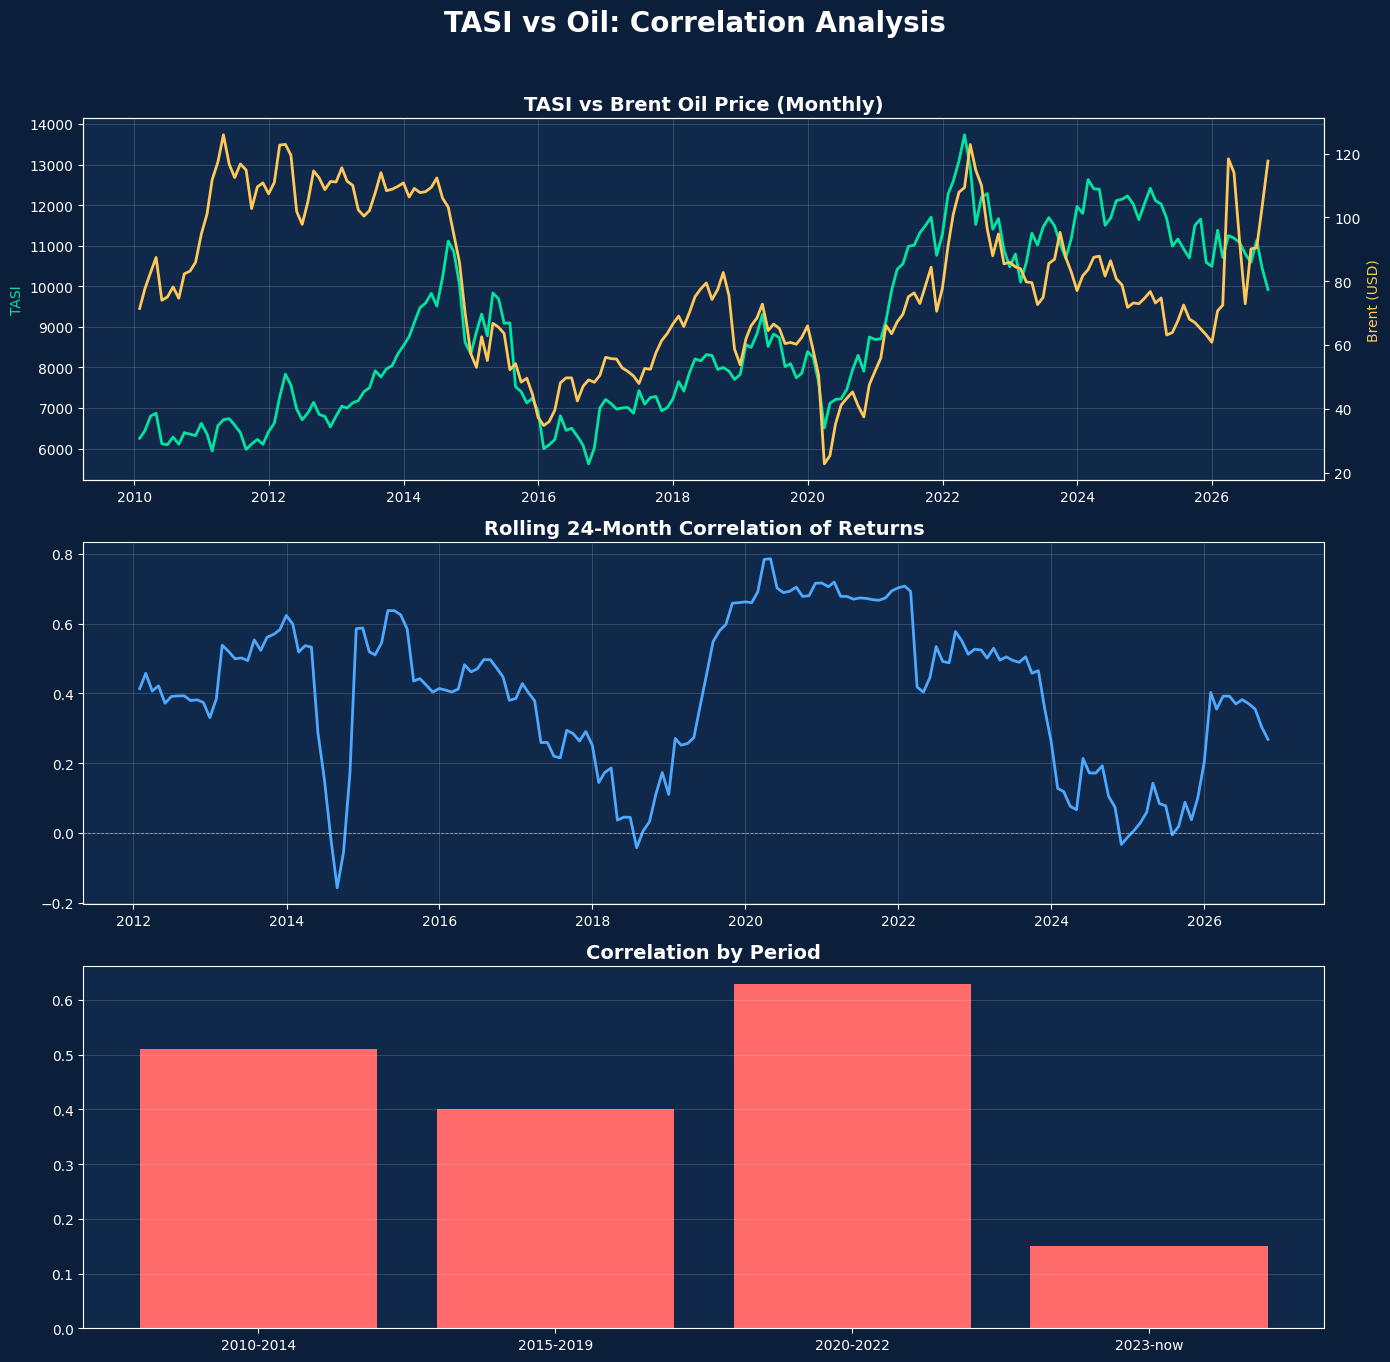

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
tasi_m = tasi.resample("ME").last()
oil_m = oil.resample("ME").last()
monthly = pd.concat([tasi_m, oil_m], axis=1).dropna()
monthly = monthly[monthly.index < "2026-11-01"]
print("Months:", len(monthly))
print(monthly.head(3))
print(monthly.tail(3))

returns = monthly.pct_change().dropna() * 100
print("Overall correlation:", round(returns["TASI"].corr(returns["Brent_Oil"]), 2))

periods = {
    "2010-2014": ("2010", "2014"),
    "2015-2019": ("2015", "2019"),
    "2020-2022": ("2020", "2022"),
    "2023-now": ("2023", "2030"),
}
rows = []
for name, (s, e) in periods.items():
    sub = returns.loc[s:e]
    if len(sub) > 6:
        rows.append({"Period": name,
                     "Correlation": round(sub["TASI"].corr(sub["Brent_Oil"]), 2),
                     "Months": len(sub)})
corr_table = pd.DataFrame(rows)
print(corr_table)

plt.style.use("dark_background")
fig, axes = plt.subplots(3, 1, figsize=(14, 14))
fig.patch.set_facecolor("#0B1F3A")

ax = axes[0]
ax.set_facecolor("#10294A")
ax.plot(monthly.index, monthly["TASI"], color="#00E5A0", linewidth=2)
ax.set_ylabel("TASI", color="#00E5A0")
ax2 = ax.twinx()
ax2.plot(monthly.index, monthly["Brent_Oil"], color="#FFC857", linewidth=2)
ax2.set_ylabel("Brent (USD)", color="#FFC857")
ax.set_title("TASI vs Brent Oil Price (Monthly)", fontsize=14, fontweight="bold")
ax.grid(alpha=0.15)

ax = axes[1]
ax.set_facecolor("#10294A")
rolling = returns["TASI"].rolling(24).corr(returns["Brent_Oil"]).dropna()
ax.plot(rolling.index, rolling, color="#4DA8FF", linewidth=2)
ax.axhline(0, color="white", linestyle="--", linewidth=0.6, alpha=0.5)
ax.set_title("Rolling 24-Month Correlation of Returns", fontsize=14, fontweight="bold")
ax.grid(alpha=0.15)

ax = axes[2]
ax.set_facecolor("#10294A")
if len(corr_table) > 0:
    ax.bar(corr_table["Period"], corr_table["Correlation"], color="#FF6B6B")
ax.axhline(0, color="white", linewidth=0.6)
ax.set_title("Correlation by Period", fontsize=14, fontweight="bold")
ax.grid(alpha=0.15, axis="y")

fig.suptitle("TASI vs Oil: Correlation Analysis", fontsize=20, fontweight="bold")
plt.tight_layout(rect=[0, 0.01, 1, 0.96])
plt.savefig("tasi_oil_dashboard.png", dpi=200, facecolor=fig.get_facecolor())
plt.show()

monthly.to_csv("TASI_Oil_Monthly.csv")
files.download("tasi_oil_dashboard.png")
files.download("TASI_Oil_Monthly.csv")